# Week 8 Feature importance and odd-year analysis

In [1]:
import zipfile
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import xgboost
from IPython.display import display
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.metrics import roc_auc_score, precision_recall_curve, auc
from sklearn.metrics import confusion_matrix
from sklearn.calibration import CalibrationDisplay
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression

zip_path = Path("csv.zip")
model_folder = Path(".")

files = {}
with zipfile.ZipFile(zip_path) as z:
    for name in z.namelist():
        if name.lower().endswith(".csv"):
            files[Path(name).name] = name

In [2]:
# Load the files saved after full-data training
preprocessor = joblib.load(model_folder / "final_preprocessor.joblib")
threshold = joblib.load(model_folder / "final_threshold.joblib")
lr_model = joblib.load(model_folder / "final_logistic_regression.joblib")
rf_model = joblib.load(model_folder / "final_random_forest.joblib")
xgb_model = joblib.load(model_folder / "final_xgboost.joblib")

# Keep the models together so the same test steps can be applied to each one
models = {
    "Logistic Regression": lr_model,
    "Random Forest": rf_model,
    "XGBoost": xgb_model
}

print("All five saved files loaded successfully.")
print("Saved threshold:", threshold)
print("Encoded columns:", len(preprocessor.get_feature_names_out()))

All five saved files loaded successfully.
Saved threshold: 0.2
Encoded columns: 89


In [3]:
# Use the same predictors and target definition
numeric_features = [
    "bmi_00",
    "mental_health_days_00",
    "physical_health_days_00"
]

categorical_features = [
    "age_00", "sex_00", "race_00", "marital_status_00", "education_00",
    "income", "gen_health_00", "exercise_00", "smoked_100_cigarettes_00",
    "drinks_alcohol_00", "had_stroke_00", "had_heart_attack_00",
    "had_coronary_heart_disease_00", "cost_barrier_00",
    "l_checkup_00", "has_personal_doctor_00"
]

predictor_columns = numeric_features + categorical_features

target_map = {
    "Diabetic": 1,
    "Non-diabetic": 0,
    "Pre-diabetic": 0
}

# Check the column order before transforming test data
assert list(preprocessor.feature_names_in_) == predictor_columns
print("Predictor order matches the saved preprocessor.")

Predictor order matches the saved preprocessor.


In [4]:
def load_year(year, extra_features=None):
    if extra_features is None:
        extra_features = []
    # Choose the income column for this year
    if year <= 2020:
        income_column = "income_00"
        income_maximum = 8
    else:
        income_column = "income_01"
        income_maximum = 11

    source_columns = numeric_features + categorical_features
    source_columns.remove("income")
    source_columns.append(income_column)
    source_columns.append("diabetes")
    source_columns += extra_features

    annual_name = "DATASET_" + str(year) + ".csv"
    with zipfile.ZipFile(zip_path) as z:
        with z.open(files[annual_name]) as f:
            raw = pd.read_csv(f, usecols=source_columns, low_memory=False)

    # Keep all records with one of the expected target labels
    original_count = len(raw)
    missing_target_count = int(raw["diabetes"].isna().sum())
    mapped_target = raw["diabetes"].map(target_map)
    unexpected_target = raw["diabetes"].notna() & mapped_target.isna()
    if unexpected_target.any():
        unexpected_labels = raw.loc[unexpected_target, "diabetes"].unique()
        raise ValueError("Unexpected diabetes labels: " + str(unexpected_labels))

    clean = raw.loc[mapped_target.notna()].copy()
    clean["target"] = mapped_target.loc[mapped_target.notna()].astype("int8")
    del raw, mapped_target

    # Match income groups across years
    income = pd.to_numeric(clean[income_column], errors="coerce")
    valid_income = income.isin(range(1, income_maximum + 1))
    income = income.where(valid_income)
    clean["income"] = income.replace({9: 8, 10: 8, 11: 8})

    # Keep records with invalid predictors, but set those values to missing
    bmi = pd.to_numeric(clean["bmi_00"], errors="coerce")
    invalid_bmi = bmi.notna() & ~bmi.between(12.00, 99.99)
    clean["bmi_00"] = bmi.where(bmi.between(12.00, 99.99))
    for feature in ["mental_health_days_00", "physical_health_days_00"]:
        values = pd.to_numeric(clean[feature], errors="coerce")
        clean[feature] = values.where(values.between(0, 30))

    clean = clean[predictor_columns + extra_features + ["target"]].copy()
    for feature in categorical_features:
        labels = clean[feature].astype("string")
        labels = labels.str.replace(r"\.0$", "", regex=True)
        labels = labels.fillna("<missing>")
        clean[feature] = labels.astype(str)
    for feature in numeric_features:
        clean[feature] = clean[feature].astype("float32")

    audit = {
        "year": year,
        "original_rows": original_count,
        "missing_target_rows": missing_target_count,
        "used_rows": len(clean),
        "positive_rows": int(clean["target"].sum()),
        "bmi_changed_to_missing": int(invalid_bmi.sum())
    }
    return clean, audit

## Compare SHAP across test years

I use XGBoost because it had the highest F1 in each of the four test years. I take a random sample of 10,000 records from each year and explain the same saved model with XGBoost’s built-in TreeSHAP.

For a feature with several encoded columns, I add its contributions for each record before taking the absolute value. Contributions are on the model's raw score scale (log-odds).

year,2021,2022,2023,2024
feature,,,,
gen_health_00,0.5191,0.5141,0.4948,0.4952
age_00,0.4621,0.4687,0.4629,0.4834
bmi_00,0.4059,0.4023,0.4082,0.4116
l_checkup_00,0.2150,0.2080,0.2014,0.1967
drinks_alcohol_00,0.1989,0.1937,0.2008,0.1938
sex_00,0.0951,0.0958,0.0974,0.0970
race_00,0.0859,0.0874,0.0878,0.0864
has_personal_doctor_00,0.0770,0.0814,0.0787,0.0780
had_heart_attack_00,0.0508,0.0532,0.0509,0.0521


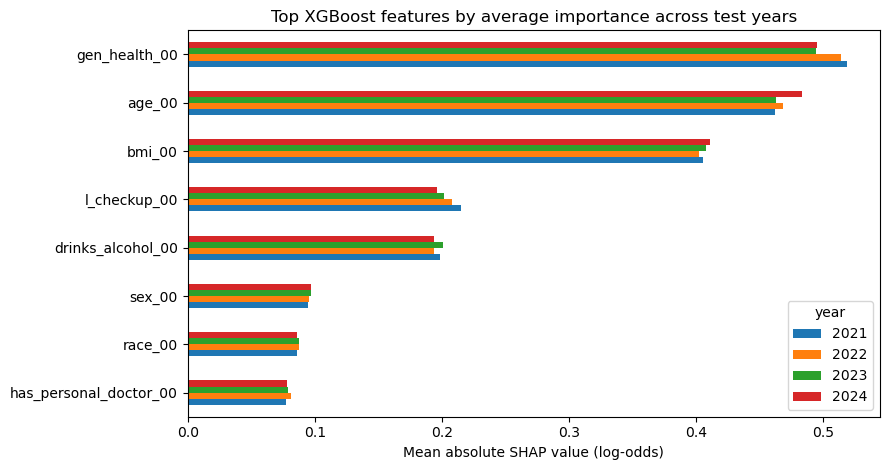

In [5]:
booster = xgb_model.get_booster()
feature_groups = {}
for feature in predictor_columns:
    feature_groups[feature] = []

# Use the fitted encoder to recover which columns belong to each feature
for i, feature in enumerate(numeric_features):
    feature_groups[feature] = [i]
encoder = preprocessor.named_transformers_["category"]
start = len(numeric_features)
for feature, categories in zip(categorical_features, encoder.categories_):
    stop = start + len(categories)
    feature_groups[feature] = list(range(start, stop))
    start = stop
assert start == len(preprocessor.get_feature_names_out())

shap_rows = []
for year in range(2021, 2025):
    data, audit = load_year(year)
    sample = data.sample(n=10000, random_state=0)
    X = preprocessor.transform(sample[predictor_columns]).astype("float32")
    matrix = xgboost.DMatrix(X)
    values = booster.predict(matrix, pred_contribs=True)
    margins = booster.predict(matrix, output_margin=True)
    np.testing.assert_allclose(values.sum(axis=1), margins, atol=0.001)
    for feature, columns in feature_groups.items():
        combined = values[:, columns].sum(axis=1)
        shap_rows.append({
            "year": year, "feature": feature,
            "mean_abs_shap": np.abs(combined).mean()
        })
    del data, sample, X, matrix, values

shap_results = pd.DataFrame(shap_rows)
shap_table = shap_results.pivot(index="feature", columns="year", values="mean_abs_shap")
order = shap_table.mean(axis=1).sort_values(ascending=False).index
display(shap_table.loc[order].round(4))

top = shap_table.loc[order[:8]].iloc[::-1]
ax = top.plot.barh(figsize=(9, 4.8))
ax.set_xlabel("Mean absolute SHAP value (log-odds)")
ax.set_ylabel("")
ax.set_title("Top XGBoost features by average importance across test years")
plt.tight_layout()
plt.show()

The top three included self-rated general health, age, and BMI in all four test years. A large value means the model uses that feature strongly, but it does not tell me the direction of the effect or prove cause and effect.

## Check the odd years separately

I fit two Logistic Regression models on the same odd-year records from 2005 to 2019. The first uses the original predictors. The second adds high blood pressure and high cholesterol. I test both models on the same records in 2021 and 2023.

For this comparison, I keep records with known values for both added features. I show how many records are kept because this restriction changes the sample. I keep the “Borderline” blood pressure response as its own category. Both preprocessors learn from training records only. I use threshold 0.20 for both models as a fixed comparison point.

In [6]:
# Extra features available only in the odd-year files
extra = ["high_bp_00", "high_cholesterol_00"]

train_years = list(range(2005, 2020, 2))
test_years = [2021, 2023]
odd_data = {}
count_rows = []

for year in train_years + test_years:
    data, audit = load_year(year, extra)

    # Keep records where both added features are available
    keep = data[extra].notna().all(axis=1)
    
    # Record how many rows are kept after this restriction
    count_rows.append({
        "year": year, 
        "known_target": len(data), 
        "used": int(keep.sum())
    })
    
    clean = data.loc[keep].copy()
    
    for col in extra:
        clean[col] = clean[col].astype(str)
    for col in categorical_features + extra:
        clean[col] = clean[col].astype("category")
    
    odd_data[year] = clean
    del data, clean

odd_counts = pd.DataFrame(count_rows)
odd_counts["kept_pct"] = 100 * odd_counts["used"] / odd_counts["known_target"]
display(odd_counts.round(2))

# Combine all odd-year training data from 2005 to 2019
# Both Logistic Regression models will use these same records
train = pd.concat([odd_data.pop(year) for year in train_years], ignore_index=True)
print("Training records used in both models:", f"{len(train):,}")

,year,known_target,used,kept_pct
0,2005,355446,288716,81.23
1,2007,429942,362355,84.28
2,2009,431636,372470,86.29
3,2011,503846,429085,85.16
4,2013,490368,418358,85.32
5,2015,439881,376723,85.64
6,2017,447952,415432,92.74
7,2019,416661,386890,92.85
8,2021,437250,372774,85.25
9,2023,431746,376074,87.11


Training records used in both models: 3,050,029


In [7]:
odd_rows = []

# Compare two Logistic Regression versions
for version, added in [("Original predictors", []), ("Add BP and cholesterol", extra)]:
    columns = predictor_columns + added
    
    # Same preprocessing structure used by the main model
    prep = clone(preprocessor)
    steps = []

    # Add BP and cholesterol only for the second model
    for name, transformer, features in prep.transformers:
        if name == "category":
            features = list(features) + added
        steps.append((name, transformer, features))
    
    prep.set_params(transformers=steps)

    # Fit only on the odd-year training records
    X_train = prep.fit_transform(train[columns]).astype("float32")

    # Train a new Logistic Regression model for this feature set
    model = clone(lr_model)
    model.fit(X_train, train["target"])
    
    del X_train

    # Test both model versions on the same 2021 and 2023 records
    for year in test_years:
        test = odd_data[year]
        X_test = prep.transform(test[columns]).astype("float32")
        y = test["target"]
        score = model.predict_proba(X_test)[:, 1]
        prediction = score >= threshold
        p, r, _ = precision_recall_curve(y, score)
        odd_rows.append({
            "year": year, "model": version, "records": len(test),
            "precision": precision_score(y, prediction, zero_division=0),
            "recall": recall_score(y, prediction, zero_division=0),
            "f1": f1_score(y, prediction, zero_division=0),
            "roc_auc": roc_auc_score(y, score), "pr_auc": auc(r, p)
        })
        del X_test

odd_results = pd.DataFrame(odd_rows).sort_values(["year", "model"])
display(odd_results.round(4))

,year,model,records,precision,recall,f1,roc_auc,pr_auc
2,2021,Add BP and cholesterol,372774,0.3694,0.6230,0.4638,0.8182,0.4143
0,2021,Original predictors,372774,0.3549,0.5979,0.4454,0.8042,0.3889
3,2023,Add BP and cholesterol,376074,0.3672,0.6335,0.4649,0.8137,0.4158
1,2023,Original predictors,376074,0.3538,0.6073,0.4472,0.7996,0.3901


In 2021, ROC-AUC rose from 0.8042 to 0.8182, and F1 rose from 0.4454 to 0.4638. In 2023, ROC-AUC rose from 0.7996 to 0.8137, and F1 rose from 0.4472 to 0.4649. 

Both versions used the same records in each test year. The comparison only covers people with both added features recorded.

## Organize results for the final report

- **Model performance over time:** From 2021 to 2024, ROC-AUC went down a little for all three models, while F1 stayed about the same. This means model performance changed only slightly across the four test years.
- **Important features:** General health, age, and BMI were the most important features for XGBoost in all four test years. The main features stayed similar from 2021 to 2024. SHAP helps show which features affect the model’s predictions, but it does not mean these features cause diabetes.
- **Blood pressure and cholesterol:** Adding high blood pressure and high cholesterol improved ROC-AUC and F1 in both 2021 and 2023. Both models used the same records, so this suggests that these two features added useful information. This is a separate analysis because these features were only available for the odd years.

The processed files do not include survey weights, so the results describe this dataset and may not represent the U.S. population. This study focuses on comparing model performance over time, the models and evaluation metrics are based on the available records rather than population-weighted estimates.